In [34]:
import torch
import torch.nn as nn
import torchvision
import torchvision.datasets as datasets
import random
import torch.nn.functional as F
import torchvision.transforms as transforms
from torchvision.transforms import v2
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from torch.utils.data import random_split
    
import numpy as np 
import matplotlib.pyplot as plt 

import itertools
import pandas as pd
import time
import math

## Pre-processing

**Define set seed function and configure our device**

In [35]:
# Hardware device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed = 67):
    """Seed every random number generator we use (67 = our group number, as in Task 1)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Using device: cuda


**Load data: train, validation and test, and standardise**

The data is standardised with the mean and std of only the training images
Only training data cause the validation/test data should remain unseen (no leakage)

For the 75 x 75 data

In [36]:
# Load clock data
clock_images = np.load("data/A1_data_75/images.npy") # Shape: (18000, 75, 75), 18000 frayscale images of size 75 x 75 
clock_labels = np.load("data/A1_data_75/labels.npy") # Shape: (18000, 2): 18000 labels of hour and minute pairs

# Convert data to tensors: (number of images, channels, height, width) format
x = torch.from_numpy(clock_images).float().unsqueeze(1) # Grayscale so channel = 1

# Scale the pixels 
if x.max().item() > 1.0:                           
    x = x / 255.0 # Convert range from [0, 255] to [0, 1]

# Convert labels as tensor to long format
y = torch.from_numpy(clock_labels).long()

# Combine images and labels into a tensor dataset
clock_all = TensorDataset(x, y) 

# Define sizes of the 80/10/10 split for the train/validate/test set 
n = len(clock_all)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

# Split the data 
clock_train, clock_validation, clock_test = random_split(
    clock_all,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(67)
)

# Standardise
train_idx = clock_train.indices
mean, std = x[train_idx].mean(), x[train_idx].std() 
x.sub_(mean).div_(std) 
print(f"train mean/std used: {mean:.4f} / {std:.4f}")


train mean/std used: 0.5971 / 0.2176


In [37]:
# Load clock data
clock150_images = np.load("data/A1_data_150/images.npy") # Shape: (18000, 75, 75), 18000 frayscale images of size 75 x 75 
clock150_labels = np.load("data/A1_data_150/labels.npy") # Shape: (18000, 2): 18000 labels of hour and minute pairs

# Convert data to tensors: (number of images, channels, height, width) format
x = torch.from_numpy(clock150_images).float().unsqueeze(1) # Grayscale so channel = 1

# Scale the pixels 
if x.max().item() > 1.0:                           
    x = x / 255.0 # Convert range from [0, 255] to [0, 1]

# Convert labels as tensor to long format
y = torch.from_numpy(clock150_labels).long()

# Combine images and labels into a tensor dataset
clock150_all = TensorDataset(x, y) 

# Define sizes of the 80/10/10 split for the train/validate/test set 
n = len(clock150_all)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

# Split the data 
clock150_train, clock150_validation, clock150_test = random_split(
    clock150_all,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(67)
)

# Standardise
train_idx = clock150_train.indices
mean, std = x[train_idx].mean(), x[train_idx].std() 
x.sub_(mean).div_(std) 
print(f"train mean/std used: {mean:.4f} / {std:.4f}")


train mean/std used: 0.5967 / 0.2214


**Visualise**

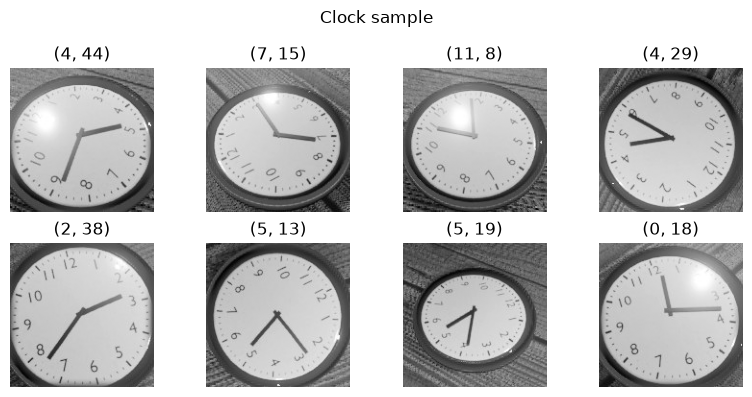

In [38]:
idxs = torch.randperm(len(x))[:8] # Indexes of random images

fig, ax = plt.subplots(2, 4, figsize=(8, 4))

for i, j in zip(idxs, ax.flat):
    hour, minute = y[i].tolist()
    j.imshow(x[i, 0], cmap = "gray")
    j.axis("off")
    j.set_title(f"({hour}, {minute})")

plt.suptitle("Clock sample")
plt.tight_layout()
plt.savefig("figures/visualise_clocks.png", dpi = 300)
plt.show()

**Creating the dataloaders**

Shuffling is set to true for the training set again to make sure that the batches are random between epochs. We don't need to shuffle for the validation and test set since we are only using those to evaluate the model. The order of images doesn't affect the overall result

We take the same batch size of Task 1 (64) to account for the fact that the images are much larger compared to what we had in task 1 (150x150, as apposed to 28x28) which requires more memory per batch. WIth 14,400 training images, this amounts to 225 updates per epoch

In [39]:
batch_size = 64

# Create the DataLoaders
clock_train_loader = DataLoader(clock_train, batch_size = batch_size, shuffle = True)
clock_validation_loader = DataLoader(clock_validation, batch_size = batch_size, shuffle = False)
clock_test_loader = DataLoader(clock_test, batch_size = batch_size, shuffle = False)

In [40]:
print(f"Number of batches in the training DataLoader: {len(clock_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(clock_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(clock_test_loader)} \n")

images, labels = next(iter(clock_train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 225
Number of batches in the validation DataLoader: 29
Number of batches in the test DataLoader: 29 

Image batch shape: torch.Size([64, 1, 75, 75])
Label batch shape: torch.Size([64, 2])
Image data type: torch.float32
Pixel range: -2.4018054008483887 1.8514466285705566


## Evaluation metric: common-sense error

In [41]:
def time_in_minutes(labels):
    """ 
    Convert the original (hour, minute) labels into minutes as hour 12 and hour 0 are the same
    Formula: t = (hour % 12) * 60 + minute 

    Examples
        (0, 0) -> 0
        (6, 0) -> 360
        (12, 0) -> 0

    Output: integer in [0, 719] 
    """
    time_minutes = (labels[:, 0] % 12) * 60 + labels[:, 1]
    return time_minutes

def common_sense_error(pred_minutes, true_minutes):
    """
    Absolute time difference between predicted and true time, taking into account the 12-hour wrap-around
    """

    # Calculate the difference between two time points in minutes
    time_diff = torch.remainder(pred_minutes - true_minutes, 720)

    # Account for the 12-hour wrap-around 
    min_diff = torch.minimum(time_diff, 720 - time_diff) # Shortest way around the clock
    return min_diff

## Model building

**`ClockNet`: CNN class similar in structure to `NeuralNetwork` of Task 1**

It has one shared CNN architecture: convolutional blocks followed by fully connected layers. THe class covers all the four experiments and only the output layer changes between them. Loss and conversion of outputs into time depend on output_type

Parameters
* output_type defines how you want to predict the time 
* n_classes: classification only, number of time classes. 24 gives 30 minute bins, 720 gives 1-minute bins
* minute_mode: multihead only, decided if minutes are predicted as 60 classes ("class") or one value ("reg")
* cnn_channels: number and size of output channels of each convolutional block
* kernel_size: size of convolutional filters. 
* batch_norm: normalizes values between batches
* hidden_dims: fully connected layers shared by all heads
* activation: activation function
* dropout: regularization term, dropout probability

Notes: put some notes about the code in here as I didn't want the clutter the code 

**NOTE 1** Batch normalization: normalizes each channel of the convolution output (zero mean, unit variance over the batch) and then rescales it with learnable parameters. It keeps the activations on a stable scale in between layers which ultimately speeds up training and makes it less sensitive to the learning rate and initialization

**NOTE 2** We want to make sure the network accepts both 75x75 and 150x150 images so we fixed a 4x4 feature map before the linear layers. We keep a 4x4 map instead of one average per channel (1x1), because the position of the clock hands carries information. 


In [42]:
class ClockNet(nn.Module):
    def __init__(self,
            output_type = "regression", # "classification", "regression", "multihead", "trig"
            n_classes = 24, # Classification only
            minute_mode = "class", # Multihead only: "class" or "reg"  
            cnn_channels = [32, 64, 128, 256], 
            kernel_size = 3, # Padding = kernel_size // 2 keeps the image size, so use odd sizes
            batch_norm = True,
            hidden_dims = [256], # Fully connected layers shared by all heads
            activation = nn.ReLU,
            dropout = 0.0):
        super().__init__()
        self.output_type = output_type

        #--------------- Shared convolutional backbone ---------------
        layers = []
        in_ch = 1 # Channels of input, only 1 as we have grayscale images here 

        # Build convolutional blocks
        for out_ch in cnn_channels:
            layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding = kernel_size // 2))

            # Batch normalization NOTE 1
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_ch))

            layers.append(activation()) # Add activation function after each convolution
            layers.append(nn.MaxPool2d(2)) # Add pooling layer

            in_ch = out_ch # Update input channel for the next layer

        self.features = nn.Sequential(*layers) # Combines the layers

        # Adaptive average pooling NOTE 2
        self.pool = nn.AdaptiveAvgPool2d(4)

        #--------------- Shared fully connected layers ---------------
        fc_layers = [nn.Flatten()] # Convert feature map into 1D vector
        input_size = cnn_channels[-1] * 4 * 4

        # Create the fully connected layers 
        for hidden_size in hidden_dims:
            fc_layers.append(nn.Linear(input_size, hidden_size)) # Connect every input neuron to every output neuron
            fc_layers.append(activation())

            # Dropouts: randomly inactivate some neurons (if applicable)
            if dropout > 0:
                fc_layers.append(nn.Dropout(dropout))
            
            input_size = hidden_size

        self.fc = nn.Sequential(*fc_layers) 

        #--------------- Output heads: no activation, they output logits/raw values ---------------
        # Different ways to interpret the extracted features
        if output_type == "classification":
            self.head = nn.Linear(input_size, n_classes) # One score (logit) per time bin
        elif output_type == "regression":
            self.head = nn.Linear(input_size, 1) # Time as a fraction of 12 hours
        elif output_type == "trig":
            self.head = nn.Linear(input_size, 4) # Sin / cos of the hour and minute angle
        elif output_type == "multihead": # Two separate output heads for hour and minute 
            self.hour_head = nn.Linear(input_size, 12)  # 12 classes for the hour (0-11)
            self.minute_head = nn.Linear(input_size, 60 if minute_mode == "class" else 1) # 60 classes for the minute (0-59) or 1 value for regression
        else:
            raise ValueError(f"Unknown output_type: {output_type!r}")

    # Take intput, process it through all layers, and return an output
    def forward(self, x):
        z = self.fc(self.pool(self.features(x))) # Combine all shared layers 

        # Return two separate outputs for multi-head prediction
        if self.output_type == "multihead":
            return self.hour_head(z), self.minute_head(z)

        # Return single output for classification/regression/trigonometric prediction
        out = self.head(z)

        # Normalise trigonometric outputs
        if self.output_type == "trig":
            # Scale each (sin, cos) pair to length 1: the prediction is then a point on the unit circle.
            # No ReLU / sigmoid: sin and cos can be negative.
            out = torch.cat([F.normalize(out[:, :2], dim = 1), F.normalize(out[:, 2:], dim = 1)], dim = 1)

        return out

## Targets, losses and decoding

**Losses**

Define the losses for any real number outputs (so for the regression, multi-head, trigonometric encoding)
* SmoothL1 uses Beta = 0.05 instead of the default 1.0, because with beta = 1 SmoothL1 would simply be 0.5 * MSE
* MSE penalizes large errors heavily (such as a hand mistaken by 180 degrees)
* L1 treats all errors lineary (absolute difference instead of squaring it) which is more robust and directly matches the minutes-based metric
* SmoothL1 is quadratic for small errors and linear for large ones. Tries to combine the advantages both MSE and L1

In [43]:
# Define different (regression) loss functions
REG_LOSSES = {
    "mse": nn.MSELoss(), 
    "l1": nn.L1Loss(), 
    "smoothl1": nn.SmoothL1Loss(beta = 0.05)}

For every formulation we need (1) the target that is built from the (hour, minute) label, (2) the loss, and (3) a way to turn the network output back into a time in minutes, so that all formulations are scored with the same common-sense error.

In [44]:
def trig_encode(labels):
    """
    Convert the time (hour, minute) into a trigonometric representation (sin, cos) for the hour and minute hand

    The hour hand makes one full turn in 12 hours (720) and moves gradually with the minutes.

    The minute hand makes one full turn in 60 minutes.
    Mapping it to the unit circle makes 11:59 and 0:01 neighbours 

    Output: shape (B,  4)
    """ 
    angle_h = 2 * math.pi * time_in_minutes(labels).float() / 720 # = 2 pi (hour + minute / 60) / 12
    angle_m = 2 * math.pi * labels[:, 1].float() / 60 # = 2 pi (minute / 60)

    # Convert the angles into sine and cosine 
    convert_angles = torch.stack([torch.sin(angle_h), torch.cos(angle_h), torch.sin(angle_m), torch.cos(angle_m)], dim = 1)

    return convert_angles


def compute_loss(outputs, labels, params): 
    """ 
    Turns the true labels into the target of the chosen formulation and compares it with the network output

    Params
        outputs: model predictions
        labels: true (hour, minute) pairs
        params: dictionary of hyperparameters
    """
    kind = params["output_type"] # Selected prediction approach 
    t = time_in_minutes(labels).float() # True time in minutes since 12:00
    hour, minute = labels[:, 0] % 12, labels[:, 1] # Separate hour and minute values   
    
    if kind == "classification":
        """ 
        Divide into equal sized bins
        # Calculate loss, F.cross_entropy applies softmax itself so the network outputs raw logits and needs no final activation
        """
        bin_size = 720 // params["n_classes"] 
        return F.cross_entropy(outputs, (t // bin_size).long())       
        
    if kind == "regression":
        """ 
        params["loss"] selects the loss object ("mse", "l1" or "smoothl1") from the REG_LOSSES dictionary
        squeeze(1) turns the (batch, 1) output into (batch, ) to match the target
        target: fraction of 12 hours, in [0, 1)
        """
        return REG_LOSSES[params["loss"]](outputs.squeeze(1), t / 720) # Target: 
    
    if kind == "multihead":
        """ 
        The model returns two outputs: 12 hour logits and a minute output (60 logits or one value)

        Join loss L = L_hour + alpha * L_minute
        Both gradients flow into the shared backbone, and the two losses have different scales (cross-entropy vs a regression loss)
        -> So alpha balances how much each head influences it
        """

        out_hour, out_minute = outputs

        # Loss of "hour"
        loss_hour = F.cross_entropy(out_hour, hour) # Hour: always 12-class classification

        # Loss of "minutes"
        if params["minute_mode"] == "class":
            loss_minute = F.cross_entropy(out_minute, minute) # Minute as 60-class classification
        else:
            loss_minute = REG_LOSSES[params["loss"]](out_minute.squeeze(1), minute / 60) # Minute as regression on [0, 1)

        return loss_hour + params["alpha"] * loss_minute

    if kind == "trig":
        """ 
        Compare the predicted (sin, cos) pairs of both hands with the true ones
        No jump at 12:00, because 11:59 and 0:01 have almost the same target on the unit circle
        """
        return REG_LOSSES[params["loss"]](outputs, trig_encode(labels))

def outputs_to_minutes(outputs, params):
    """
    Turn network outputs into a predicted time in minutes since 12:00 
    The wrap-around is handled by common_sense_error)

    Inverse of compute_loss function: let all formulations be scored with the same metric
    """
    kind = params["output_type"]

    if kind == "classification":
        bin_size = 720 // params["n_classes"]
        return outputs.argmax(1).float() * bin_size + (bin_size - 1) / 2 # Centre of the predicted bin

    if kind == "regression":
        return outputs.squeeze(1) * 720 # Undo the scaling to [0, 1)

    if kind == "multihead":
        out_hour, out_minute = outputs
        if params["minute_mode"] == "class":
            minute = out_minute.argmax(1).float()
        else:
            minute = out_minute.squeeze(1) * 60 # Undo the scaling to [0, 1)
        return out_hour.argmax(1).float() * 60 + minute # Hour and minute are decided independently

    if kind == "trig":
        # Recover each hand's angles using atan2(sin, cos). % 2 pi maps it to [0, 2 pi)
        angle_h = torch.atan2(outputs[:, 0], outputs[:, 1]) % (2 * math.pi) # Hour-hand angle in [0, 2 pi)
        angle_m = torch.atan2(outputs[:, 2], outputs[:, 3]) % (2 * math.pi) # Minute-hand angle

        # Convert angles into time estimates
        rough = angle_h / (2 * math.pi) * 720 # Rough time from hour hand 
        minute = angle_m / (2 * math.pi) * 60 # Exact minute from the minute hand

        # NOTE since hour hand is a rough time, pick the hour (0...11) for which 60 * h + minute is closest to the rough time
        hours = torch.arange(12, device = outputs.device).float().view(1, 12) # Generate all possible hours 
        candidates = hours * 60 + minute.view(-1, 1) # Combine every possible hour with the predicted minute

        # Find the candidates closest to the hour-hand estimates
        diff = torch.remainder(candidates - rough.view(-1, 1), 720) # Circular distance to the hour-hand estimate
        diff = torch.minimum(diff, 720 - diff)
        return candidates.gather(1, diff.argmin(1, keepdim = True)).squeeze(1) # Keep the closest candidate

**Sanity check !!**

Perfect trigonometric outputs must decode back to the true time (error ~ 0)

If we give the decoding function perfect predictions it should give the original time 

In [45]:
# Create example times
check = torch.tensor([[0, 5], [11, 55], [3, 0], [2, 34], [7, 59]]) # (hour, minute)

# Decode
decoded = outputs_to_minutes(trig_encode(check), {"output_type": "trig"})

# Calculate error (should be ~ 0)
print(common_sense_error(decoded, time_in_minutes(check).float()))

tensor([0., 0., 0., 0., 0.])


## Training

Four helper functions
* `make_optimizer` 
* `evaluate` evaluates how well the model performs
* `region_errors` checks how the model performs around 12:00
* `plot_history` to visualise training process


In [46]:
def make_optimizer(model, name, learning_rate, weight_decay = 0.0, momentum = 0.9):
    if name == "SGD":
        return optim.SGD(model.parameters(), lr = learning_rate, momentum = momentum, weight_decay = weight_decay)
    if name == "Adam":
        return optim.Adam(model.parameters(), lr = learning_rate, weight_decay = weight_decay)
    if name == "AdamW":
        return optim.AdamW(model.parameters(), lr = learning_rate, weight_decay = weight_decay)
    raise ValueError(f"Unknown optimizer: {name!r}")

@torch.no_grad() # NOTE no gradients needed for evaluation: saves memory and time
def evaluate(model, loader, params):
    """
    Evaluates the model on a dataset 

    Average loss, mean common-sense error, and the per-image predicted / true times (in minutes)
    """
    model.eval() # Switch model to evaluation mode: BatchNorm uses its running statistics and dropout is switched off

    loss_total, n = 0.0, 0
    preds, trues = [], []

    # Iterate over the batches
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)

        # NOTE compute_loss returns the average loss for one batch
        # Multiply by batch size (labels.size(0)) to get the total loss for that batch
        # This gives the exact average over all images
        loss_total += compute_loss(outputs, labels, params).item() * labels.size(0)
        n += labels.size(0)

        # Convert every formulation to minutes, so all of them are scored with the same metric
        preds.append(outputs_to_minutes(outputs, params).cpu())
        trues.append(time_in_minutes(labels).float().cpu())

    preds, trues = torch.cat(preds), torch.cat(trues)
    mean_error = common_sense_error(preds, trues).mean().item()

    return loss_total / n, mean_error, preds, trues # NOTE preds and trues are returned as well for the error analysis

def region_errors(pred, true, window = 30):
    """
    Mean error for times within `window` minutes of 12:00 (where the 12 -> 0 wrap-around is) and for all other times
    
    Check whether a formulation struggles at the 12:00 boundary , compared to the rest of the clock face
        e.g. plain regression, which doesn't know that the clock is circular

    window = 30, so images where the time is between [00:00, 00:29] and [11:31, 11:59] are selected
    """
    error = common_sense_error(pred, true)
    near = (true < window) | (true > 720 - window) # Identify times close to 12:00 

    return error[near].mean().item(), error[~near].mean().item()

def plot_history(history):
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4))

    # Loss Plot: the training objective, not comparable between formulations
    ax1.plot(epochs_range, history["train_loss"], marker = "o", label = "Train Loss")
    ax1.plot(epochs_range, history["val_loss"], marker = "o", label = "Validation Loss")
    ax1.set_title("Training loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    # Error Plot: common-sense error in minutes. The metric we actually want to minimise and it's comparable between formulations
    # NOTE a growing gap between train and validation indicates overfitting
    ax2.plot(epochs_range, history["train_err"], marker = "o", label = "Train Error")
    ax2.plot(epochs_range, history["val_err"], marker = "o", label = "Validation Error")
    ax2.set_title("Common-sense error")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Error (minutes)")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

`run_experiment` follows the same structure as the training function of Task 1: hyperparameters in a dictionary, DataLoaders, model and optimizer, a training and validation loop, restoring the best weights, and an optional test evaluation. The differences are:

* **Formulation-dependent loss and prediction.** The loss comes from `compute_loss`, and the predictions are converted to minutes with `outputs_to_minutes`. The metric is the common-sense error in minutes, not the accuracy.
* **Best epoch by validation error.** The model we keep is the one with the lowest validation error, since that is the quantity we want to minimize. The losses of different formulations cannot be compared with each other.
* **Learning rate schedule.** We add a cosine decay of the learning rate over all epochs.
* **Test set on request only.** The test set is evaluated only with `evaluate_test = True`, so it is never used to choose hyperparameters.
* **Per-image predictions.** The best model's predictions are stored in `history`, which is used for the error analysis (errors near 12:00, error histograms, example images).

In [47]:
# MODEL_KEYS specifies which hyperparameters ClockNet.__init__ needs
# params dictionary also holds training settings (learning rate, epochs, ...) which aren't needed to create the CNN 
MODEL_KEYS = ("output_type", "n_classes", "minute_mode", "cnn_channels", "kernel_size",
              "batch_norm", "hidden_dims", "activation", "dropout")

def run_experiment(params, train = None, validation = None, test = None,
                   plotting = False, evaluate_test = False, verbose = False):
    
    # Use the 75 x 75 datasets by default
    train = clock_train if train is None else train
    validation = clock_validation if validation is None else validation
    test = clock_test if test is None else test

    # Seeding at the start of every run makes the runs reproducible and comparable (same initial weights and batch order)
    set_seed(params["seed"])
    if params["output_type"] == "classification":
        # The bin size is 720 // n_classes, so check if n_classes give equal sized bins
        assert 720 % params["n_classes"] == 0, "n_classes must divide 720 (24, 72, 144, 720, ...)"

    # Record time to see how long the experiment takes
    start_time = time.time()

    # Create DataLoaders 
    # NOTE only the training data is shuffled, the order of the validation/test data stays fixed
    # This makes sure the predictions line up with the images, which is needed for the plots at the end
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model and the optimizer
    model = ClockNet(**{key: params[key] for key in MODEL_KEYS}).to(device) # NOTE only the keys the model needs are passed on
    optimizer = make_optimizer(model, params["optimizer"], params["learning_rate"], params["weight_decay"])

    # Learning rate schedule: cosine decay from the learning rate to 0 over all epochs
    # NOTE large steps early on, small steps at the end for fine convergence
    scheduler = None
    if params["scheduler"] == "cosine":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max = params["epochs"])

    # Store losses and errors for each epoch
    history = {"train_loss": [], "val_loss": [], "train_err": [], "val_err": []}
    best_val_loss, best_val_err, best_epoch, best_model_state = np.inf, np.inf, 0, None

    for epoch in range(params["epochs"]):
        #---------- Training Phase ----------
        model.train() # Switch model to training mode 
        loss_total, err_total, n = 0.0, 0.0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = compute_loss(outputs, labels, params) # NOTE the loss depends on the formulation (output_type)
            loss.backward()
            optimizer.step()

            # Training performance (average over the epoch, measured in train mode)
            loss_total += loss.item() * labels.size(0)
            with torch.no_grad(): # Only for measuring, not part of the training
                err = common_sense_error(outputs_to_minutes(outputs, params), time_in_minutes(labels).float())
            err_total += err.sum().item()
            n += labels.size(0)

        history["train_loss"].append(loss_total / n)
        history["train_err"].append(err_total / n)

        #---------- Validation Phase ----------
        val_loss, val_err, _, _ = evaluate(model, validation_loader, params)
        history["val_loss"].append(val_loss)
        history["val_err"].append(val_err)

        # Update the learning rate
        # NOTE the scheduler is stepped once per epoch, after the optimizer updates of that epoch
        if scheduler is not None:
            scheduler.step()

        # Print training process if verbose = True
        if verbose:
            print(f"Epoch {epoch + 1:>3}/{params['epochs']} | train loss {history['train_loss'][-1]:.4f} | "
                  f"val loss {val_loss:.4f} | train err {history['train_err'][-1]:.1f} | val err {val_err:.1f} min")

        # Save the model with the lowest validation ERROR 
        # NOTE not loss: the losses of different formulations are not comparable, and the error is what we want to minimise 
        if val_err < best_val_err:
            best_val_loss, best_val_err, best_epoch = val_loss, val_err, epoch + 1
            # Copy weights to the CPU
            # NOTE this is because state_dict() returns references that would otherwise be overwritten by the next training steps
            best_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

        # Stop if training diverged (NaN / inf), e.g. with a learning rate that is too high
        if not np.isfinite(val_loss):
            break

    # Restore the best weights, so the model we return and evaluate is the best epoch, not the last one
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    history["best_epoch"] = best_epoch

    # Per-image predictions of the best model on the validation set (used for the error analysis)
    _, _, history["val_pred"], history["val_true"] = evaluate(model, validation_loader, params)

    #---------- Test Phase (only if evaluate_test = True) ----------
    # Only evaluated for the final runs, so hyperparameters are never chosen using the test set
    test_loss, test_err = None, None
    if evaluate_test:
        test_loss, test_err, history["test_pred"], history["test_true"] = evaluate(model, test_loader, params)

    print(f"  done in {time.time() - start_time:.0f}s | best validation error {best_val_err:.2f} min (epoch {best_epoch})")
    if plotting:
        plot_history(history)

    # Test values are None unless evaluate_test = True
    return model, history, best_val_loss, best_val_err, test_loss, test_err


### Grid search

In [48]:
def run_grid(base_params, grid):
    """
    Run every combination of the values in `grid` ({parameter name: list of values}) on top of `base_params`
        e.g. {"loss": ["mse", "l1"]}, {"learning_rate": [1e-3, 3e-4], "dropout": [0.0, 0.3]}

    Returns a results table (best first) and the parameters of the best run.
    Besides the validation error, the table shows the error near 12:00 and elsewhere, to see whether a setting struggles at the wrap-around

    Only the validation set is used
    """
    rows, best_err, best_params = [], np.inf, None

    # NOTE itertools.product gives every combination of the lists, e.g. 2 learning rates x 2 dropouts = 4 runs
    for values in itertools.product(*grid.values()):
        changes = dict(zip(grid.keys(), values)) # The settings of this run, e.g. {"loss": "l1"}
        print("Testing ->", changes)
        params = {**base_params, **changes} # The changes that override the base parameters

        # Use only the validation set here (run_experiment doesn't touch the test set by default)
        model, history, val_loss, val_err, _, _ = run_experiment(params)

        # Split the error into times near 12:00 (wrap-around region) and all other times
        near, elsewhere = region_errors(history["val_pred"], history["val_true"])
        rows.append({
            "Formulation": params["output_type"],
            "Setting": ", ".join(f"{key}={value}" for key, value in changes.items()),
            "Val Err (min)": round(val_err, 2),
            "Err near 12:00": round(near, 2),
            "Err elsewhere": round(elsewhere, 2),
            "Best epoch": history["best_epoch"],
            "Params": sum(p.numel() for p in model.parameters()), # Model size, to see the cost of wider networks
        })
        
        # Keep the full parameter dictionary of the run with the lowest validation error, so it can be reused later
        if best_params is None or val_err < best_err:
            best_err, best_params = val_err, params

    results = pd.DataFrame(rows).sort_values("Val Err (min)").reset_index(drop = True)
    return results, best_params


## Experiments on the 75x75 images (validation set)

Parameters

* Output: `output_type` ("classification", "regression", "multihead", "trig"), `n_classes`, `minute_mode`, `alpha`, `loss` ("mse", "l1", "smoothl1")
* Architecture: `cnn_channels`, `kernel_size`, `batch_norm`, `hidden_dims`, `activation`, `dropout`
* Optimizer: `optimizer`, `learning_rate`, `weight_decay`, `scheduler`
* Training: `epochs`, `batch_size`, `seed`

First a baseline (regression with the L1 loss) with training curves.

Epoch   1/20 | train loss 0.3733 | val loss 0.2306 | train err 174.7 | val err 159.7 min
Epoch   2/20 | train loss 0.2079 | val loss 0.1866 | train err 144.1 | val err 129.7 min
Epoch   3/20 | train loss 0.1751 | val loss 0.1744 | train err 121.7 | val err 118.7 min
Epoch   4/20 | train loss 0.1507 | val loss 0.1384 | train err 105.4 | val err 96.8 min
Epoch   5/20 | train loss 0.1275 | val loss 0.1220 | train err 89.6 | val err 86.2 min
Epoch   6/20 | train loss 0.1097 | val loss 0.1018 | train err 77.5 | val err 72.2 min
Epoch   7/20 | train loss 0.0950 | val loss 0.1085 | train err 67.4 | val err 76.6 min
Epoch   8/20 | train loss 0.0871 | val loss 0.0875 | train err 61.9 | val err 62.0 min
Epoch   9/20 | train loss 0.0753 | val loss 0.0785 | train err 53.7 | val err 56.0 min
Epoch  10/20 | train loss 0.0670 | val loss 0.0803 | train err 47.9 | val err 56.6 min
Epoch  11/20 | train loss 0.0617 | val loss 0.0738 | train err 44.1 | val err 52.6 min
Epoch  12/20 | train loss 0.0547 | v

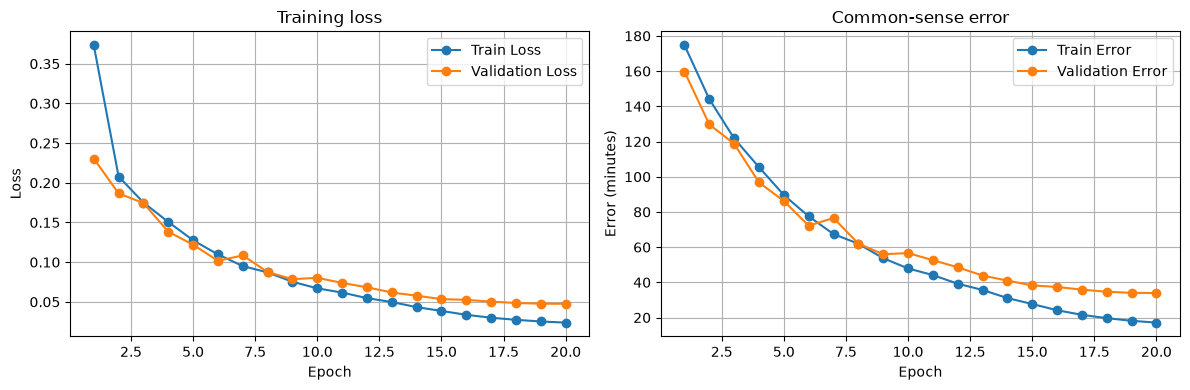


Baseline results:
Best Validation Error: 33.95 minutes (epoch 20) | Parameters: 1,437,889


In [49]:
base_params = {
    # Output formulation
    "output_type": "regression", # "classification", "regression", "multihead" or "trig"
    "n_classes": 24, # Classification only, must divide 720
    "minute_mode": "class", # Multihead only, "class" (60 classes) or "reg" (one value)
    "alpha": 1.0, # Multihead only: L = L_hour + alpha * L_minute
    "loss": "l1", # For real-valued outputs: "mse", "l1" or "smoothl1"

    # Architecture
    "cnn_channels": [32, 64, 128, 256],
    "kernel_size": 3,
    "batch_norm": True,
    "hidden_dims": [256],
    "activation": nn.ReLU,
    "dropout": 0.0,

    # Optimizer
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "weight_decay": 0.0,
    "scheduler": "cosine", # "cosine" or None

    # Training
    "epochs": 20,
    "batch_size": 64,
    "seed": 67
}

model0, history0, val_loss0, val_err0, _, _ = run_experiment(base_params, plotting = True, verbose = True)

print("\nBaseline results:")
print(f"Best Validation Error: {val_err0:.2f} minutes (epoch {history0['best_epoch']}) | Parameters: {sum(p.numel() for p in model0.parameters()):,}")

### 1. Classification

Bins of 30 / 10 / 5 / 1 minutes (24 / 72 / 144 / 720 classes). The predicted time is the centre of the predicted bin.

*For the report:* what happens to the error when the number of classes grows? Think about the number of training images per class (14,400 / 720 = 20), about neighbouring classes being treated as completely unrelated by the cross-entropy loss, and about the size of the output layer.

In [50]:
grid_cls = {"n_classes": [24, 72, 144, 720]}
results_cls, best_cls = run_grid({**base_params, "output_type": "classification"}, grid_cls)
display(results_cls)

Testing -> {'n_classes': 24}
  done in 95s | best validation error 9.60 min (epoch 17)
Testing -> {'n_classes': 72}
  done in 95s | best validation error 21.68 min (epoch 19)
Testing -> {'n_classes': 144}
  done in 95s | best validation error 177.08 min (epoch 1)
Testing -> {'n_classes': 720}
  done in 96s | best validation error 178.27 min (epoch 1)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,classification,n_classes=24,9.60,9.79,9.59,17,1443800
1,classification,n_classes=72,21.68,21.28,21.71,19,1456136
2,classification,n_classes=144,177.08,160.82,178.37,1,1474640
3,classification,n_classes=720,178.27,88.82,185.35,1,1622672


### 2. Regression

One output (time as a fraction of 12 hours). Which loss is best? Look at the columns **Err near 12:00** (true time within 30 minutes of 12:00) and **Err elsewhere**.

*For the report:* 11:59 and 0:01 are 2 minutes apart, but as numbers they are almost the whole range apart (0.998 vs 0.001). The loss cannot know that the clock is circular, and the images around 12:00 look almost identical, so the network is pulled towards both ends.

In [51]:
grid_reg = {"loss": ["mse", "l1", "smoothl1"]}
results_reg, best_reg = run_grid({**base_params, "output_type": "regression"}, grid_reg)
display(results_reg)

Testing -> {'loss': 'mse'}
  done in 95s | best validation error 72.91 min (epoch 20)
Testing -> {'loss': 'l1'}
  done in 95s | best validation error 33.16 min (epoch 20)
Testing -> {'loss': 'smoothl1'}
  done in 95s | best validation error 33.33 min (epoch 19)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,regression,loss=l1,33.16,89.24,28.72,20,1437889
1,regression,loss=smoothl1,33.33,81.94,29.48,19,1437889
2,regression,loss=mse,72.91,156.57,66.29,20,1437889


### 3. Multi-head

Shared backbone, two heads: `out_hour, out_minute = model(x)`. The hour head always classifies the 12 hours. The minute head either classifies the 60 minutes (`"class"`) or regresses `minute / 60` (`"reg"`). Joint loss: L = L_hour + alpha x L_minute. The cross-entropy and the regression loss have a different scale, so alpha is explored for both.

*For the report:* compare with the single-output models above. Which mistakes are typical (hint: around the full hour, when the hour hand is almost on a number and the hour and minute heads can disagree)?

In [52]:
grid_multi = {"minute_mode": ["class", "reg"], "alpha": [0.5, 1.0, 5.0]}
results_multi, best_multi = run_grid({**base_params, "output_type": "multihead"}, grid_multi)
display(results_multi)

Testing -> {'minute_mode': 'class', 'alpha': 0.5}
  done in 95s | best validation error 6.37 min (epoch 20)
Testing -> {'minute_mode': 'class', 'alpha': 1.0}
  done in 95s | best validation error 28.97 min (epoch 18)
Testing -> {'minute_mode': 'class', 'alpha': 5.0}
  done in 95s | best validation error 177.32 min (epoch 4)
Testing -> {'minute_mode': 'reg', 'alpha': 0.5}
  done in 95s | best validation error 8.45 min (epoch 20)
Testing -> {'minute_mode': 'reg', 'alpha': 1.0}
  done in 95s | best validation error 7.92 min (epoch 17)
Testing -> {'minute_mode': 'reg', 'alpha': 5.0}
  done in 95s | best validation error 49.06 min (epoch 20)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,multihead,"minute_mode=class, alpha=0.5",6.37,5.25,6.46,20,1456136
1,multihead,"minute_mode=reg, alpha=1.0",7.92,9.78,7.77,17,1440973
2,multihead,"minute_mode=reg, alpha=0.5",8.45,7.25,8.55,20,1440973
3,multihead,"minute_mode=class, alpha=1.0",28.97,25.27,29.26,18,1456136
4,multihead,"minute_mode=reg, alpha=5.0",49.06,81.43,46.50,20,1440973
5,multihead,"minute_mode=class, alpha=5.0",177.32,205.82,175.06,4,1456136


### 4. Trigonometric encoding

The hands are angles, so we predict the points on the unit circle (sin, cos) of the hour-hand angle and of the minute-hand angle. Design of the output layer (see `ClockNet`):
* 4 linear outputs, no ReLU / sigmoid (sin and cos are in [-1, 1] and can be negative).
* Each (sin, cos) pair is scaled to length 1, so the output is a valid point on the circle. Loss: MSE or L1 against the true (sin, cos).
* Decoding: `atan2` gives the two angles. The minute comes from the minute hand (exact), the hour from the hour hand (rough): we choose the hour for which the time fits the hour hand best. Because 11:59 and 0:01 are neighbours on the circle, there is no discontinuity at 12:00.

In [53]:
grid_trig = {"loss": ["mse", "l1"]}
results_trig, best_trig = run_grid({**base_params, "output_type": "trig"}, grid_trig)
display(results_trig)

Testing -> {'loss': 'mse'}
  done in 97s | best validation error 3.29 min (epoch 19)
Testing -> {'loss': 'l1'}
  done in 86s | best validation error 2.32 min (epoch 20)


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,loss=l1,2.32,1.96,2.35,20,1438660
1,trig,loss=mse,3.29,4.75,3.17,19,1438660


### Comparison of the formulations (validation set)

The best run of every formulation, and the winner.

In [54]:
best_configs = {"classification": best_cls, "regression": best_reg, "multihead": best_multi, "trig": best_trig}

all_results = pd.concat([results_cls, results_reg, results_multi, results_trig])
all_results = all_results.sort_values("Val Err (min)").reset_index(drop = True)
display(all_results)

summary = all_results.drop_duplicates("Formulation").reset_index(drop = True)    # best run per formulation
display(summary)

winner = summary.loc[0, "Formulation"]
print("Best formulation on the validation set:", winner)

,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,loss=l1,2.32,1.96,2.35,20,1438660
1,trig,loss=mse,3.29,4.75,3.17,19,1438660
2,multihead,"minute_mode=class, alpha=0.5",6.37,5.25,6.46,20,1456136
3,multihead,"minute_mode=reg, alpha=1.0",7.92,9.78,7.77,17,1440973
4,multihead,"minute_mode=reg, alpha=0.5",8.45,7.25,8.55,20,1440973
5,classification,n_classes=24,9.60,9.79,9.59,17,1443800
6,classification,n_classes=72,21.68,21.28,21.71,19,1456136
7,multihead,"minute_mode=class, alpha=1.0",28.97,25.27,29.26,18,1456136
8,regression,loss=l1,33.16,89.24,28.72,20,1437889
9,regression,loss=smoothl1,33.33,81.94,29.48,19,1437889


,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,loss=l1,2.32,1.96,2.35,20,1438660
1,multihead,"minute_mode=class, alpha=0.5",6.37,5.25,6.46,20,1456136
2,classification,n_classes=24,9.60,9.79,9.59,17,1443800
3,regression,loss=l1,33.16,89.24,28.72,20,1437889


Best formulation on the validation set: trig


### Backbone tuning

Learning rate, width and dropout for the winning formulation (a small grid; add `weight_decay`, `kernel_size`, ... if you have time).

In [55]:
grid_backbone = {
    "learning_rate": [1e-3, 3e-4],
    "cnn_channels": [[32, 64, 128, 256], [64, 128, 256, 512]],
    "dropout": [0.0, 0.3]
}
results_backbone, best_backbone = run_grid(best_configs[winner], grid_backbone)
display(results_backbone)

Testing -> {'learning_rate': 0.001, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.0}
  done in 86s | best validation error 1.70 min (epoch 19)
Testing -> {'learning_rate': 0.001, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.3}
  done in 97s | best validation error 9.34 min (epoch 20)
Testing -> {'learning_rate': 0.001, 'cnn_channels': [64, 128, 256, 512], 'dropout': 0.0}
  done in 202s | best validation error 2.31 min (epoch 20)
Testing -> {'learning_rate': 0.001, 'cnn_channels': [64, 128, 256, 512], 'dropout': 0.3}
  done in 203s | best validation error 7.57 min (epoch 19)
Testing -> {'learning_rate': 0.0003, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.0}
  done in 97s | best validation error 6.49 min (epoch 20)
Testing -> {'learning_rate': 0.0003, 'cnn_channels': [32, 64, 128, 256], 'dropout': 0.3}
  done in 97s | best validation error 14.06 min (epoch 20)
Testing -> {'learning_rate': 0.0003, 'cnn_channels': [64, 128, 256, 512], 'dropout': 0.0}
  done in 202s | best valid

,Formulation,Setting,Val Err (min),Err near 12:00,Err elsewhere,Best epoch,Params
0,trig,"learning_rate=0.001, cnn_channels=[32, 64, 128...",1.70,0.57,1.78,19,1438660
1,trig,"learning_rate=0.001, cnn_channels=[64, 128, 25...",2.31,1.33,2.38,20,3650180
2,trig,"learning_rate=0.0003, cnn_channels=[64, 128, 2...",4.31,3.71,4.36,20,3650180
3,trig,"learning_rate=0.0003, cnn_channels=[32, 64, 12...",6.49,5.67,6.56,20,1438660
4,trig,"learning_rate=0.001, cnn_channels=[64, 128, 25...",7.57,7.80,7.55,19,3650180
5,trig,"learning_rate=0.0003, cnn_channels=[64, 128, 2...",8.00,6.54,8.11,18,3650180
6,trig,"learning_rate=0.001, cnn_channels=[32, 64, 128...",9.34,9.33,9.34,20,1438660
7,trig,"learning_rate=0.0003, cnn_channels=[32, 64, 12...",14.06,12.76,14.16,20,1438660


## Final results on the 150x150 images (test set)

All four formulations are trained on the 150x150 images with their best settings from above and the tuned backbone. We select the final model with the **validation** error; the test error is only reported.

In [56]:
final_epochs = 30


tuned = {key: best_backbone[key] for key in ("learning_rate", "cnn_channels", "dropout")}
final_rows, final_runs = [], {}

for name, config in best_configs.items():
    print(f"Final training -> {name}")
    params = {**config, **tuned, "epochs": final_epochs}
    model, history, val_loss, val_err, test_loss, test_err = run_experiment(
        params, clock150_train, clock150_validation, clock150_test, evaluate_test = True, verbose = True)

    near, elsewhere = region_errors(history["test_pred"], history["test_true"])
    final_rows.append({
        "Formulation": name,
        "Val Err (min)": round(val_err, 2),
        "Test Err (min)": round(test_err, 2),
        "Test near 12:00": round(near, 2),
        "Test elsewhere": round(elsewhere, 2)
    })
    final_runs[name] = (model, history)

final_table = pd.DataFrame(final_rows).sort_values("Val Err (min)").reset_index(drop = True)
display(final_table)

Final training -> classification
Epoch   1/30 | train loss 3.2105 | val loss 3.1802 | train err 180.4 | val err 177.4 min
Epoch   2/30 | train loss 3.1786 | val loss 3.1798 | train err 180.2 | val err 177.4 min
Epoch   3/30 | train loss 3.1784 | val loss 3.1795 | train err 179.6 | val err 182.6 min
Epoch   4/30 | train loss 3.1783 | val loss 3.1794 | train err 180.2 | val err 182.6 min
Epoch   5/30 | train loss 3.1783 | val loss 3.1793 | train err 179.8 | val err 182.6 min
Epoch   6/30 | train loss 3.1782 | val loss 3.1793 | train err 180.0 | val err 182.6 min
Epoch   7/30 | train loss 3.1782 | val loss 3.1793 | train err 179.3 | val err 182.6 min
Epoch   8/30 | train loss 3.1782 | val loss 3.1792 | train err 179.8 | val err 182.6 min
Epoch   9/30 | train loss 3.1781 | val loss 3.1791 | train err 180.8 | val err 182.6 min
Epoch  10/30 | train loss 3.1781 | val loss 3.1792 | train err 179.8 | val err 182.6 min
Epoch  11/30 | train loss 3.1781 | val loss 3.1792 | train err 179.8 | val er

KeyboardInterrupt: 

### Error analysis of the final model

In [ ]:
best_name = final_table.loc[0, "Formulation"]
final_model, final_history = final_runs[best_name]
errors = common_sense_error(final_history["test_pred"], final_history["test_true"])

print(f"Final model: {best_name}")
print(f"Test error: mean {errors.mean():.2f} | median {errors.median():.2f} | 90th percentile {errors.quantile(0.9):.2f} minutes")
for tolerance in (1, 5, 10, 30):
    print(f"Within {tolerance:>2} minutes: {100 * (errors <= tolerance).float().mean():.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4))
ax1.hist(errors.numpy(), bins = 50)
ax1.set_title("Distribution of the test errors")
ax1.set_xlabel("Common-sense error (minutes)")
ax1.set_ylabel("Number of test images")

ax2.scatter(final_history["test_true"].numpy() / 60, errors.numpy(), s = 5)
ax2.set_title("Error versus true time")
ax2.set_xlabel("True time (hours since 12:00)")
ax2.set_ylabel("Common-sense error (minutes)")
plt.tight_layout()
plt.show()

In [ ]:
def clock_string(minutes):
    minutes = int(round(float(minutes))) % 720
    return f"{minutes // 60}:{minutes % 60:02d}"

# Some test images with the true and the predicted time
fig, ax = plt.subplots(3, 3, figsize = (9, 9))
for i, axis in enumerate(ax.flatten()):
    image, _ = clock150_test[i]
    axis.imshow(image.squeeze(), cmap = "gray")
    axis.set_title(f"true {clock_string(final_history['test_true'][i])} | pred {clock_string(final_history['test_pred'][i])} "
                   f"| error {errors[i]:.0f} min", fontsize = 8)
    axis.axis("off")
plt.tight_layout()
plt.show()

torch.save(final_model.state_dict(), "clock_model.pt")